In [334]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sklearn
from sklearn import preprocessing

# Data preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

Process for CW1 went as follows:

Classification
1. One hot encoding (categorical features to binary) | Imputation (using mode, old method) 
Note: there were null values '?' that were not handled before one hot encoding
2. Normalisation (MinMax, numerical features -> 0-1 range)

Regression
1. Imputation (removed null data, mean for continuous, mode for categorical)
2. Normalisation (MinMax)
3. One hot encoding (pd.get_dummies)

Possible other methods for preprocessing include:
- Removing outliers
- VAE/Bootstrapping
    - Generating new instances from not a lot of data
        - Training data after removing outliers
        - Test data with only 3 samples

And some more implicit methods include:
- Separating data into features and outcomes/labels

In [335]:
# viewing data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
    # object: ID Column
    # float64: Continuous features
    # int64: Categorical features

### Handling object datatype
1. Remove object datatype

This only contains the ID column

In [336]:
# Handling object datatype
print(dataset.select_dtypes(object)) # ID Column

print("Before: "+str(dataset.select_dtypes(object).shape))

dataset = dataset.drop("ID",axis=1)
print("After: "+str(dataset.select_dtypes(object).shape))


            ID
0    TRG002174
1    TRG002178
2    TRG002204
3    TRG002206
4    TRG002210
..         ...
395  TRG002948
396  TRG002954
397  TRG002958
398  TRG002961
399  TRG002962

[400 rows x 1 columns]
Before: (400, 1)
After: (400, 0)


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but not categorical data (doesn't use classes)


In [337]:
print(dataset.select_dtypes(np.int64))

print("Before: "+str(dataset.select_dtypes(np.int64).shape))

dataset['original_shape_VoxelVolume'] = dataset['original_shape_VoxelVolume'].astype(float)
print("After: "+str(dataset.select_dtypes(np.int64).shape))

categorical_names = dataset.select_dtypes(np.int64).columns
categorical_names

     pCR (outcome)  ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  \
0                1   0    0     0                1           3              3   
1                0   1    1     0                0           3              3   
2                1   0    0     0                1           2              1   
3                0   0    0     0                1           3              3   
4                0   1    0     0                0           2              1   
..             ...  ..  ...   ...              ...         ...            ...   
395              0   1    0     1                0           3              2   
396              0   0    0     0                1           3              3   
397              0   0    0     0                1           2              1   
398              0   1    0     0                0           3              3   
399              0   1    0     0                0           2              1   

     HistologyType  LNStatu

Index(['pCR (outcome)', 'ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade',
       'Proliferation', 'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')

### Handling float64 datatype
#### Continuous Features

Nothing specific left, data is all continuous

In [338]:
# Before
dataset.select_dtypes(np.float64)
continuous_names = dataset.select_dtypes(np.float64).columns
continuous_names

Index(['RelapseFreeSurvival (outcome)', 'Age', 'original_shape_Elongation',
       'original_shape_Flatness', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=109)

## General Preprocessing
1. Null handling
2. Outlier handling
3. Data Normalisation

In [339]:
# 1. Null Handling
    # Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
        # FIXED by taking column names for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float

# Replace 999 (placeholder) with actual null values
dataset = dataset.replace([999],np.nan)

# Viewing features with null values
non_null = dataset.isnull().sum()
non_null = non_null[non_null > 0]
non_null

pCR (outcome)       5
PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

In [340]:
# Null values can be removed or imputed
    # Or a combination of both
    # Consider only removing Gene null values, as other totals are minimal

# Removal
dataset = dataset.dropna()
dataset.info()

# Imputation
    # Impute using various methods if necessary

<class 'pandas.core.frame.DataFrame'>
Index: 308 entries, 0 to 399
Columns: 120 entries, pCR (outcome) to original_ngtdm_Strength
dtypes: float64(118), int64(2)
memory usage: 291.2 KB


In [341]:
# 2. Outlier handling 
    # Option 1 - Remove
        # all the data is outliers so no(?)
            # possibly bootstrap dataset to make more data after removing outliers...
            # use VAE instead to do so
    # Option 2 - idk more research needed: https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/

In [342]:
# Option 1

# from scipy import stats

# dataset = dataset[(np.abs(stats.zscore(dataset)) < 3).all(axis=1)]
# dataset = dataset[(np.abs(stats.zscore(dataset)) < 2).all(axis=1)]
# dataset

In [343]:
Q1 = dataset.quantile(0.25)
Q3 = dataset.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

upper_array = np.where(dataset >= upper)[0]
lower_array = np.where(dataset <= lower)[0]

# dataset.drop(index=upper_array, inplace=True)
# dataset.drop(index=lower_array, inplace=True)

<Axes: >

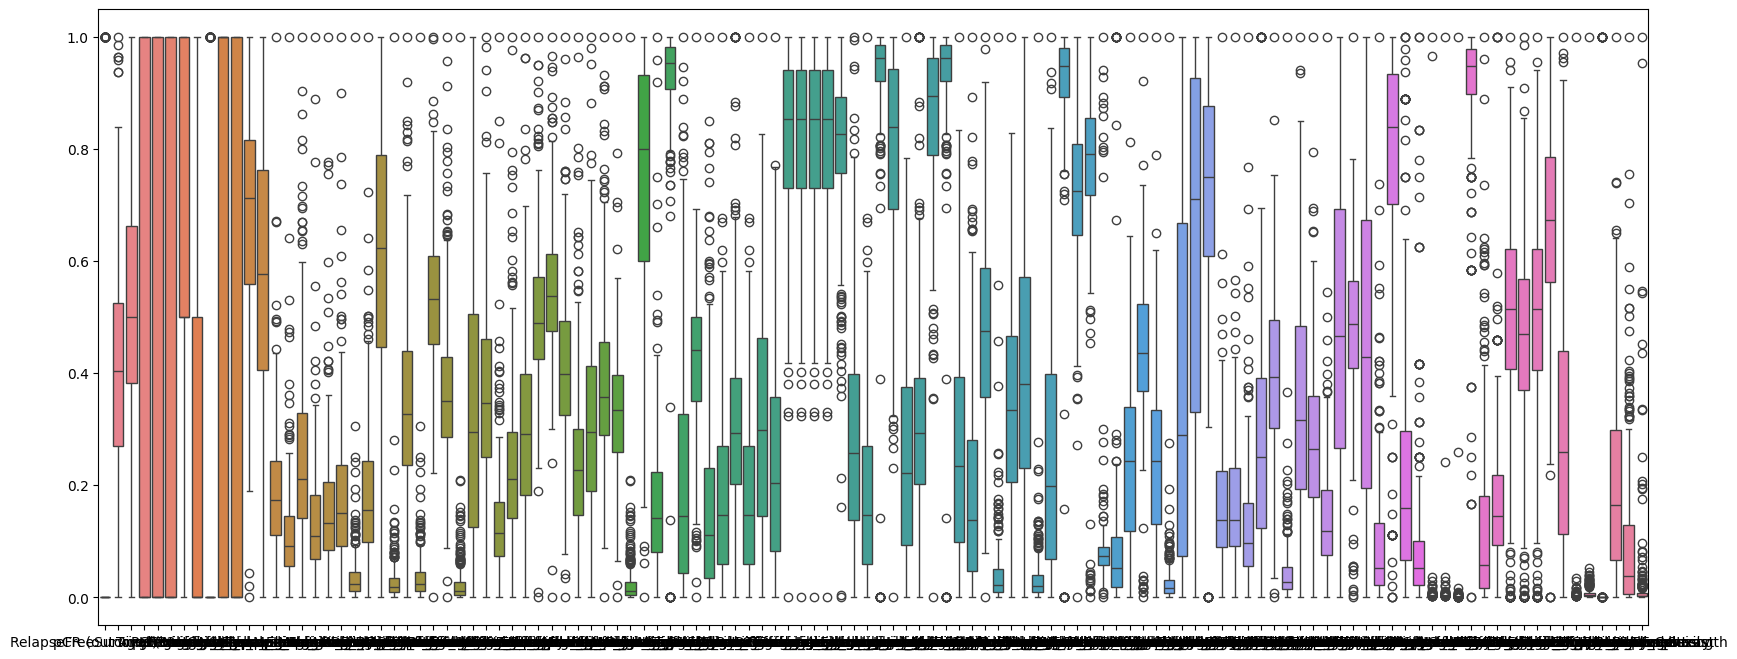

In [344]:
# 3. Normalisation
    # Minmax
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
dataset[dataset.select_dtypes(np.float64).columns] = scaler.fit_transform(dataset[dataset.select_dtypes(np.float64).columns])
dataset[dataset.select_dtypes(np.float64).columns]

import seaborn as sns

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=dataset[dataset.select_dtypes(np.float64).columns],ax=ax)